<a href="https://colab.research.google.com/github/kangyeson/AI-Class/blob/main/1026/mobile_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# 구글 드라이브 마운트
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import mean_squared_error, accuracy_score, classification_report

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import torch.optim as optim

sns.set_theme(style="whitegrid")

In [3]:
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/mobile.csv")

# 1. 데이터 구조 확인

In [4]:
print("데이터 크기:", df.shape)

print("\n처음 5개 데이터")
display(df.head())

print("\n데이터 정보")
df.info()

데이터 크기: (2000, 21)

처음 5개 데이터


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1



데이터 정보
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     2000 non-null   int64  
 7   m_dep          2000 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  px_height      2000 non-null   int64  
 12  px_width       2000 non-null   int64  
 13  ram            2000 non-null   int64  
 14  sc_h           2000 non-null   int64  
 15  sc_w           2000 non-null   int64  
 16  talk_time      2000 non-null   int64  
 17  three_g        2000 non-null   int64  
 18  

# 2. 결측치와 중복 데이터 확인

In [5]:
print("변수별 결측치 개수")
print(df.isnull().sum())

print("\n중복 행 개수")
print(df.duplicated().sum())

변수별 결측치 개수
battery_power    0
blue             0
clock_speed      0
dual_sim         0
fc               0
four_g           0
int_memory       0
m_dep            0
mobile_wt        0
n_cores          0
pc               0
px_height        0
px_width         0
ram              0
sc_h             0
sc_w             0
talk_time        0
three_g          0
touch_screen     0
wifi             0
price_range      0
dtype: int64

중복 행 개수
0


# 3. battery_power를 4개 클래스로 나누기
`pd.qcut`은 데이터 개수가 같아지도록 구간을 나눔 (4개로 나누면 각 구간에 25%씩)

In [6]:
target_col = "battery_power"

df["battery_class"], bins = pd.qcut(
    df[target_col], q=4, labels=[0, 1, 2, 3], retbins=True
)
df["battery_class"] = df["battery_class"].astype(int)

print("구간 경계값:", bins.round(2))

for i in range(4):
    print(f"클래스 {i}: {bins[i]:.0f} ~ {bins[i+1]:.0f}")

구간 경계값: [ 501.    851.75 1226.   1615.25 1998.  ]
클래스 0: 501 ~ 852
클래스 1: 852 ~ 1226
클래스 2: 1226 ~ 1615
클래스 3: 1615 ~ 1998


# 4. 레이블 종류와 개수 확인

In [7]:
print("레이블 종류")
print(df["battery_class"].unique())

print("\n레이블별 개수")
print(df["battery_class"].value_counts())

레이블 종류
[0 1 3 2]

레이블별 개수
battery_class
0    500
1    500
3    500
2    500
Name: count, dtype: int64


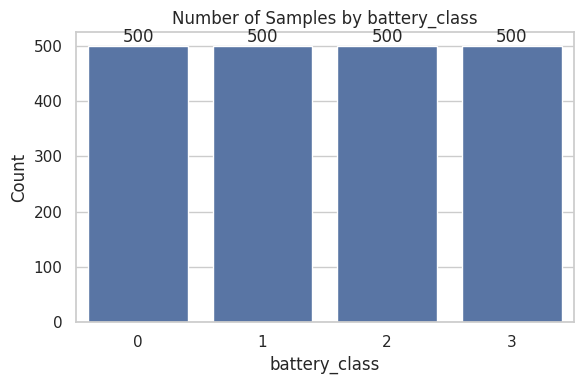

In [8]:
plt.figure(figsize=(6, 4))

ax = sns.countplot(data=df, x="battery_class")

for container in ax.containers:
    ax.bar_label(container)

plt.title("Number of Samples by battery_class")
plt.xlabel("battery_class")
plt.ylabel("Count")

plt.tight_layout()
plt.show()

**확인 결과**
- 레이블 종류: 0, 1, 2, 3 (4개 클래스)
  - 0: 501 ~ 852 / 1: 852 ~ 1226 / 2: 1226 ~ 1615 / 3: 1615 ~ 1998
- 클래스별로 500개씩 → 비어있는 클래스가 없고 개수가 완전히 균형 (qcut으로 개수가 같게 나눴기 때문)

# 5. 입력 변수 지정과 상관관계 확인

In [9]:
feature_cols = [
    col for col in df.columns
    if col not in [target_col, "battery_class", "price_range"]
]

target_corr = (
    df[feature_cols + [target_col]]
    .corr()[target_col]
    .drop(target_col)
    .sort_values(key=lambda x: x.abs(), ascending=False)
)

print("battery_power와 상관관계가 높은 변수 순서")
display(target_corr.to_frame("Correlation").round(3))

top_cols = target_corr.abs().sort_values(ascending=False).head(6).index.tolist()
print("\n상위 6개 변수:", top_cols)

battery_power와 상관관계가 높은 변수 순서


,Correlation
talk_time,0.053
dual_sim,-0.042
m_dep,0.034
fc,0.033
pc,0.031
sc_h,-0.030
n_cores,-0.030
sc_w,-0.021
four_g,0.016
px_height,0.015



상위 6개 변수: ['talk_time', 'dual_sim', 'm_dep', 'fc', 'pc', 'sc_h']


**확인 결과**
- 가장 높은 talk_time도 상관계수가 약 0.05 → **모든 입력 변수가 battery_power와 거의 관계가 없음** (회귀 실습과 같은 결과)
- 회귀 실습과 같은 조건으로 비교하기 위해 상위 6개 변수(`top_cols`)를 입력으로 사용

# 6. 클래스별 평균 확인

In [10]:
print("battery_class별 평균")
display(df.groupby("battery_class")[top_cols].mean().round(3))

print("battery_class별 표준편차")
display(df.groupby("battery_class")[top_cols].std().round(3))

battery_class별 평균


,talk_time,dual_sim,m_dep,fc,pc,sc_h
battery_class,,,,,,
0,10.626,0.550,0.488,4.152,9.720,12.400
1,11.088,0.494,0.503,4.218,9.944,12.424
2,10.916,0.506,0.491,4.282,9.860,12.356
3,11.414,0.488,0.526,4.586,10.142,12.046


battery_class별 표준편차


,talk_time,dual_sim,m_dep,fc,pc,sc_h
battery_class,,,,,,
0,5.461,0.498,0.292,4.244,5.966,4.199
1,5.339,0.500,0.282,4.303,5.997,4.210
2,5.355,0.500,0.289,4.421,6.183,4.179
3,5.680,0.500,0.290,4.396,6.120,4.265


**확인 결과**
- 클래스 0 → 3으로 가도 6개 변수의 평균이 거의 변하지 않음 (예: talk_time 10.6 / 11.1 / 10.9 / 11.4)
- 클래스 간 평균 차이가 표준편차보다 훨씬 작음 → 이 변수들로 클래스를 구별하기 어려움

# 7. 클래스별 변수 분포 비교 (Box Plot)

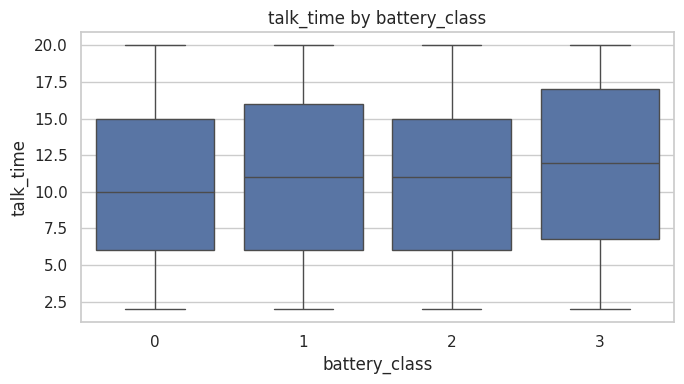

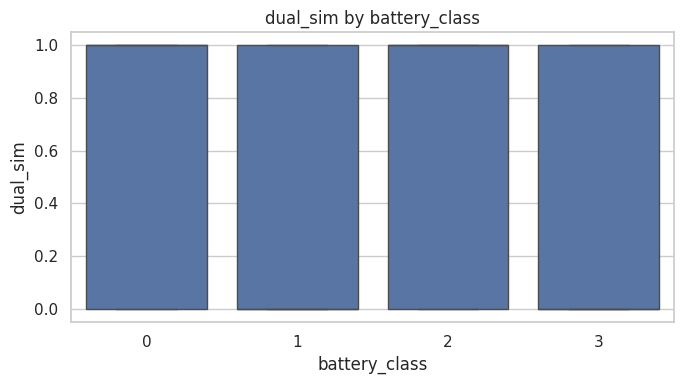

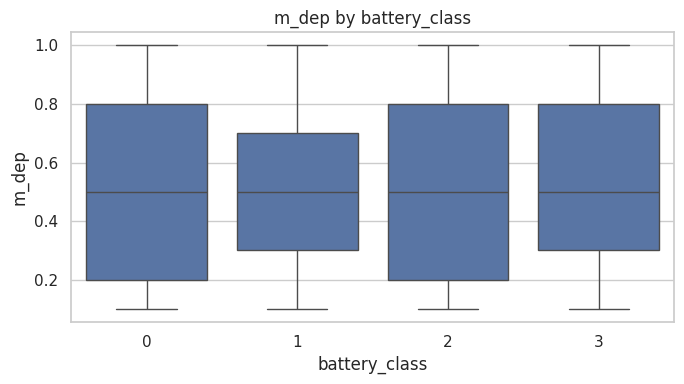

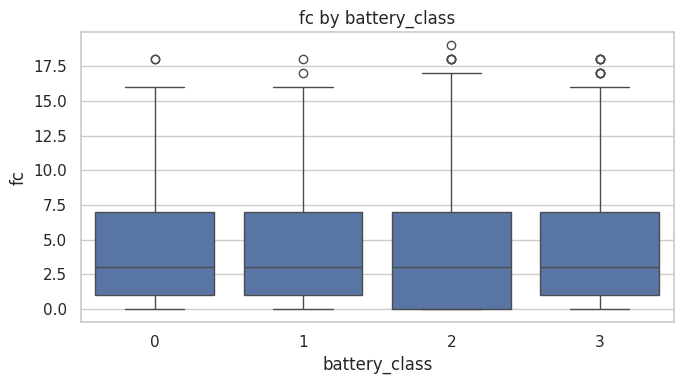

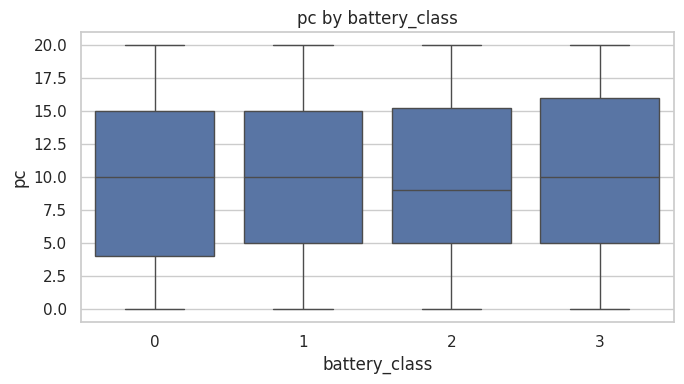

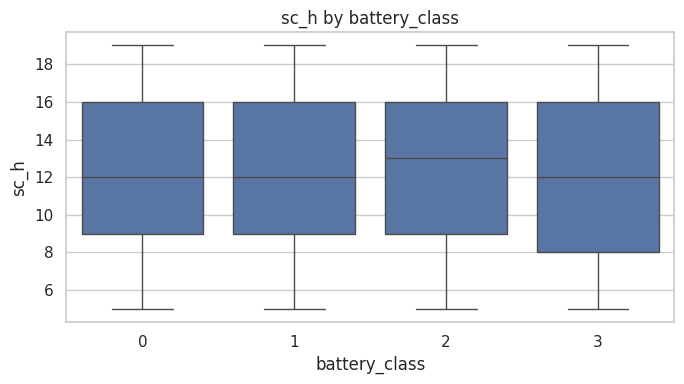

In [11]:
for col in top_cols:
    plt.figure(figsize=(7, 4))

    sns.boxplot(data=df, x="battery_class", y=col)

    plt.title(f"{col} by battery_class")

    plt.tight_layout()
    plt.show()

**확인 결과**: 4개 클래스의 박스 위치와 크기가 거의 같음 → 클래스마다 변수 분포가 겹쳐서 구별할 수 있는 기준이 없음

# 8. 학습 데이터 준비
- 입력: 상관관계 상위 6개 변수 (회귀 실습과 동일)
- 방법 1용 정답: battery_power 연속값
- 방법 2용 정답: battery_class → 원-핫 인코딩
- 한 번에 나눠서 두 방법 모두 **같은 train/test 데이터**를 사용

In [12]:
X = df[top_cols].values
y_reg = df[target_col].values.astype(np.float32)      # 방법 1: 연속값
y_cls = df["battery_class"].values                    # 방법 2: 클래스

# 정답 레이블 원-핫 인코딩
encoder = OneHotEncoder(sparse_output=False)
y_onehot = encoder.fit_transform(y_cls.reshape(-1, 1))

print("원-핫 인코딩 결과:")
print(y_onehot[:5])

# 학습 데이터와 테스트 데이터 분리
X_train, X_test, y_reg_train, y_reg_test, y_train, y_test = train_test_split(
    X, y_reg, y_onehot,
    test_size=0.2,
    random_state=42,
    stratify=y_cls
)

# 표준화
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)

# 정답 클래스 (0~3)
y_test_label = y_test.argmax(axis=1)
y_train_label = y_train.argmax(axis=1)

print("\nTrain:", X_train.shape, " Test:", X_test.shape)

원-핫 인코딩 결과:
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [1. 0. 0. 0.]
 [1. 0. 0. 0.]
 [0. 0. 0. 1.]]

Train: (1600, 6)  Test: (400, 6)


# 9. 기준선: 무작위로 찍었을 때
클래스가 4개이고 개수가 같으므로, 아무렇게나 찍어도 정답 확률은 **1/4 = 25%**.
모델은 최소한 25%보다 높아야 의미가 있음

# 10. 방법 1: 연속값 예측 후 클래스로 변환


In [13]:
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_reg_train, dtype=torch.float32).view(-1, 1)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_reg_test, dtype=torch.float32).view(-1, 1)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32)

In [14]:
class RegressionModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(6, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)          # 마지막 층: 연속값 1개, activation 없음
        )

    def forward(self, x):
        return self.model(x)

reg_model = RegressionModel()
reg_criterion = nn.MSELoss()
reg_optimizer = optim.Adam(reg_model.parameters(), lr=0.001)

In [15]:
epochs = 100
reg_loss_history = []

reg_model.train()
for epoch in range(epochs):
    total_loss = 0

    for X_batch, y_batch in train_loader:
        reg_optimizer.zero_grad()
        output = reg_model(X_batch)
        loss = reg_criterion(output, y_batch)
        loss.backward()
        reg_optimizer.step()

        total_loss += loss.item()

    reg_loss_history.append(total_loss / len(train_loader))

    if (epoch + 1) % 10 == 0:
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {total_loss / len(train_loader):.4f}")

Epoch [10/100], Loss: 329638.0631
Epoch [20/100], Loss: 205664.6722
Epoch [30/100], Loss: 199181.1078
Epoch [40/100], Loss: 195790.8075
Epoch [50/100], Loss: 193084.4163
Epoch [60/100], Loss: 191534.1505
Epoch [70/100], Loss: 190257.6963
Epoch [80/100], Loss: 189314.2552
Epoch [90/100], Loss: 188477.8081
Epoch [100/100], Loss: 188023.3881


In [16]:
reg_model.eval()
reg_preds = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        outputs = reg_model(X_batch).numpy().flatten()
        reg_preds.extend(outputs)

reg_mse = mean_squared_error(y_reg_test, reg_preds)
print(f"Test MSE: {reg_mse:.4f}")

# 예측한 연속값을 3번의 구간 경계로 클래스(0~3)로 변환
# 범위를 벗어나는 예측값도 들어가도록 양 끝 경계를 넓힘
cut_bins = bins.copy()
cut_bins[0] = 0
cut_bins[-1] = 3000

reg_pred_class = pd.cut(reg_preds, bins=cut_bins, labels=[0, 1, 2, 3]).astype(int)

reg_acc = accuracy_score(y_test_label, reg_pred_class)
print(f"방법 1 Accuracy: {reg_acc * 100:.2f}%")

print("\n예측값 범위:", round(min(reg_preds), 2), "~", round(max(reg_preds), 2))
print("\n예측 클래스별 개수")
print(pd.Series(reg_pred_class).value_counts().sort_index())

Test MSE: 207027.8594
방법 1 Accuracy: 22.75%

예측값 범위: 1036.49 ~ 1630.39

예측 클래스별 개수
1    198
2    200
3      2
Name: count, dtype: int64


**확인 결과**
- Accuracy 약 23% → 무작위로 찍는 것(25%)보다도 낮음
- 예측값이 약 1045 ~ 1640으로 평균(약 1239) 근처에만 몰려 있음
- 그래서 예측 클래스가 거의 1, 2에만 나오고, 0은 하나도 예측하지 못함
- → 회귀 실습처럼 모델이 "평균값"만 예측하므로, 양 끝 클래스(0, 3)를 맞힐 수 없음

# 11. 방법 2: 처음부터 4개 클래스로 분류

### 11-1. 기본 분류 모델: Random Forest

In [17]:
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train_label)

rf_pred = rf.predict(X_test)
rf_acc = accuracy_score(y_test_label, rf_pred)

print(f"Random Forest Accuracy: {rf_acc * 100:.2f}%")

Random Forest Accuracy: 25.00%


### 11-2. 인공신경망

In [18]:
# NumPy -> PyTorch Tensor
X_train_t = torch.tensor(X_train, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)

y_train_t = torch.tensor(y_train, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32)

In [19]:
# 신경망 모델 정의
class BatteryModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(6, 128),
            nn.ReLU(),
            nn.Linear(128, 4)         # 마지막 층: 클래스 4개, activation 없음
        )

    def forward(self, x):
        return self.network(x)

model = BatteryModel()

In [20]:
# Loss와 Optimizer 설정
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# 모델 학습
epochs = 500
loss_history = []

for epoch in range(epochs):
    model.train()

    outputs = model(X_train_t)
    loss = criterion(outputs, y_train_t)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())

    if (epoch + 1) % 50 == 0:
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}")

Epoch [50/500], Loss: 0.1897
Epoch [100/500], Loss: 0.1854
Epoch [150/500], Loss: 0.1835
Epoch [200/500], Loss: 0.1822
Epoch [250/500], Loss: 0.1809
Epoch [300/500], Loss: 0.1798
Epoch [350/500], Loss: 0.1786
Epoch [400/500], Loss: 0.1774
Epoch [450/500], Loss: 0.1763
Epoch [500/500], Loss: 0.1752


In [21]:
# 테스트 데이터 평가
model.eval()

with torch.no_grad():
    predictions = model(X_test_t)

    test_mse = criterion(predictions, y_test_t).item()

    # 가장 높은 출력값을 가진 클래스를 예측값으로 선택
    predicted_classes = predictions.argmax(dim=1)

    accuracy = accuracy_score(y_test_label, predicted_classes.numpy())

print("Test MSE:", round(test_mse, 4))
print(f"방법 2 Accuracy: {accuracy * 100:.2f}%")

print("\n클래스별 성능")
print(classification_report(y_test_label, predicted_classes.numpy()))

Test MSE: 0.1925
방법 2 Accuracy: 23.25%

클래스별 성능
              precision    recall  f1-score   support

           0       0.22      0.19      0.20       100
           1       0.23      0.27      0.25       100
           2       0.24      0.19      0.21       100
           3       0.25      0.28      0.26       100

    accuracy                           0.23       400
   macro avg       0.23      0.23      0.23       400
weighted avg       0.23      0.23      0.23       400



**확인 결과**
- Random Forest 약 25%, 신경망 약 26% → 무작위로 찍는 것(25%)과 같은 수준
- 클래스별 성능도 모든 클래스가 20 ~ 30%로 비슷함 → 특정 클래스를 잘 맞히는 것이 아니라 그냥 찍는 수준
  - precision: 그 클래스라고 예측한 것 중 실제로 맞은 비율
  - recall: 실제 그 클래스인 것 중 맞게 찾아낸 비율
- 방법 1과 달리 0 ~ 3을 골고루 예측하지만, 맞히는 비율은 여전히 25% 근처

# 12. 학습 Loss 변화

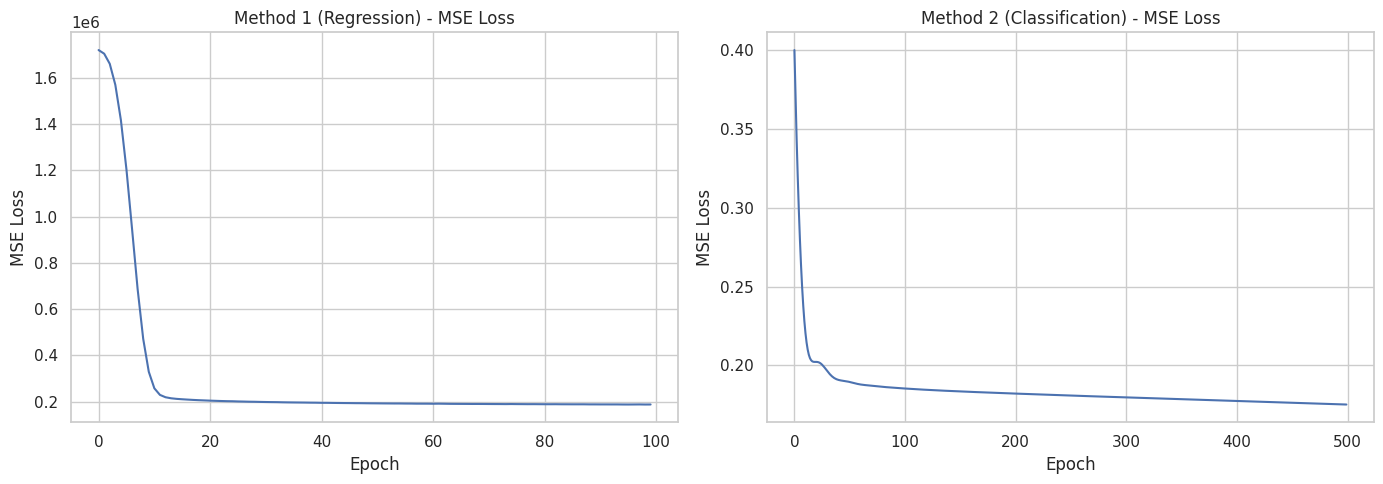

In [22]:
# 두 방법의 epoch별 학습 Loss 변화
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

axs[0].plot(reg_loss_history)
axs[0].set_title("Method 1 (Regression) - MSE Loss")
axs[0].set_xlabel("Epoch")
axs[0].set_ylabel("MSE Loss")

axs[1].plot(loss_history)
axs[1].set_title("Method 2 (Classification) - MSE Loss")
axs[1].set_xlabel("Epoch")
axs[1].set_ylabel("MSE Loss")

plt.tight_layout()
plt.show()

**확인 결과**
- 방법 1: 처음에는 Loss가 크게 줄지만(예측값이 평균 근처로 이동), 이후 약 19만 근처에서 거의 줄지 않음 (회귀 실습과 같음)
- 방법 2: Loss가 처음부터 약 0.19 근처에서 아주 조금씩만 줄어듦
  - 0.1875는 모든 클래스에 똑같이 25%씩 점수를 줄 때의 MSE → 모델이 클래스를 구별하는 방법을 거의 배우지 못함
  - Test MSE(약 0.19)가 Train Loss보다 높음 → 조금 줄어든 부분도 train 데이터를 외운 것일 뿐, test에서는 효과가 없음

# 13. 전체 결과 비교

In [23]:
print("무작위로 찍었을 때 : 25.00%")
print(f"방법 1 (연속값 예측 → 클래스 변환) : {reg_acc * 100:.2f}%")
print(f"방법 2 Random Forest             : {rf_acc * 100:.2f}%")
print(f"방법 2 인공신경망                : {accuracy * 100:.2f}%")

무작위로 찍었을 때 : 25.00%
방법 1 (연속값 예측 → 클래스 변환) : 22.75%
방법 2 Random Forest             : 25.00%
방법 2 인공신경망                : 23.25%


# 14. 결과 분석

### (1) 결과 요약
- 두 방법 모두 무작위로 찍는 것(25%)과 거의 같음
- 방법 1은 평균 근처 값만 예측해서 양 끝 클래스를 못 맞히고, 방법 2는 골고루 예측하지만 맞히는 비율이 낮음

### (2) 성능이 낮은 이유
1. **입력 변수와 battery_power의 상관관계가 거의 없음**: 모든 변수가 0.06 미만
2. **클래스별로 입력 변수의 평균과 분포가 거의 같음**: Box Plot에서 4개 클래스가 거의 겹침
3. **회귀든 분류든 결과가 같음** → 문제를 푸는 방법(모델, 회귀/분류)의 문제가 아니라, 입력 변수에 battery_power를 예측할 정보가 없는 데이터의 문제

### (3) 결론
battery_power를 연속값으로 예측하든, 4개 구간으로 나눠 분류하든 무작위 수준(약 25%)의 정확도밖에 나오지 않는다.
성능을 높이려면 배터리 용량과 관련 있는 변수(예: 실제 사용 시간, 배터리 크기 등)가 더 필요하다.